In [1]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
import tensorflow as tf
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Dense, Dropout
import joblib
from tensorflow.keras.callbacks import EarlyStopping

C:\Users\marek\AppData\Roaming\Python\Python312\site-packages\sklearn\utils\_param_validation.py:11: UserWarning: A NumPy version >=1.23.5 and <2.3.0 is required for this version of SciPy (detected version 2.3.1)
  from scipy.sparse import csr_matrix, issparse

A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.3.1 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\marek\AppData\Roaming\Python\Python312\site-packages\ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "C:\Users\

ImportError: 
A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.3.1 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.




A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.3.1 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\marek\AppData\Roaming\Python\Python312\site-packages\ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "C:\Users\marek\AppData\Roaming\Python\Python312\site-packages\traitlets\config\application.py", line 1075, in launch_instance
    app.start()
  File "C:\Users\marek\AppData\Roaming\Python\Python312\site-packages\ipykernel\kernelapp.py", line 739, in start
    self.io_lo

ImportError: 
A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.3.1 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.




A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.3.1 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\marek\AppData\Roaming\Python\Python312\site-packages\ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "C:\Users\marek\AppData\Roaming\Python\Python312\site-packages\traitlets\config\application.py", line 1075, in launch_instance
    app.start()
  File "C:\Users\marek\AppData\Roaming\Python\Python312\site-packages\ipykernel\kernelapp.py", line 739, in start
    self.io_lo

ImportError: 
A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.3.1 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.



SystemError: initialization of _pywrap_checkpoint_reader raised unreported exception

In [2]:
data = pd.read_csv("C:\\Users\\marek\\Documents\\Datasets\\Projekt\\hospital_readmissions.csv")

# Show first raws
print(data.head())

       age  time_in_hospital  n_lab_procedures  n_procedures  n_medications  \
0  [70-80)                 8                72             1             18   
1  [70-80)                 3                34             2             13   
2  [50-60)                 5                45             0             18   
3  [70-80)                 2                36             0             12   
4  [60-70)                 1                42             0              7   

   n_outpatient  n_inpatient  n_emergency medical_specialty       diag_1  \
0             2            0            0           Missing  Circulatory   
1             0            0            0             Other        Other   
2             0            0            0           Missing  Circulatory   
3             1            0            0           Missing  Circulatory   
4             0            0            0  InternalMedicine        Other   

        diag_2       diag_3 glucose_test A1Ctest change diabetes_med

In [3]:
# Split the data into features (X) and target (y)
X = data.drop('readmitted', axis=1)
y = data['readmitted'].map({'yes': 1, 'no': 0})  # Convert 'yes'/'no' to 1/0


In [4]:
# Ensure numerical data for the model
X = X.apply(pd.to_numeric, errors='coerce')

In [5]:
# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [6]:
# Save feature order to ensure consistency during prediction
feature_order = X.columns.tolist()
with open('feature_order.txt', 'w') as f:
    f.write('\n'.join(feature_order))

In [7]:
# Standardize the data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

C:\Users\marek\AppData\Roaming\Python\Python312\site-packages\sklearn\utils\extmath.py:1137: RuntimeWarning: invalid value encountered in divide
  updated_mean = (last_sum + new_sum) / updated_sample_count
C:\Users\marek\AppData\Roaming\Python\Python312\site-packages\sklearn\utils\extmath.py:1142: RuntimeWarning: invalid value encountered in divide
  T = new_sum / new_sample_count
C:\Users\marek\AppData\Roaming\Python\Python312\site-packages\sklearn\utils\extmath.py:1162: RuntimeWarning: invalid value encountered in divide
  new_unnormalized_variance -= correction**2 / new_sample_count


In [10]:
import joblib
# Save the scaler for future use
joblib.dump(scaler, 'scaler.pkl')


['scaler.pkl']

In [10]:
# Check for missing values
print(y_train.isnull().sum())
print(y_test.isnull().sum())

0
0


In [11]:
# Check if the data type of y_train and y_test is integer
print(y_train.dtypes)
print(y_test.dtypes)

int64
int64


In [12]:
# Building the model
model = tf.keras.Sequential([
    tf.keras.layers.Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(1, activation='sigmoid')  # Wyjście dla binary classification
])


C:\Users\marek\AppData\Roaming\Python\Python312\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [13]:
# Compiling the model
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])


In [14]:
# EarlyStopping
es = EarlyStopping(
    monitor='val_loss',
    mode='min',
    patience=10,
    restore_best_weights=True
)

In [15]:
# Training the model
history = model.fit(X_train, y_train, epochs=50, batch_size=32, validation_split=0.2)


Epoch 1/50
500/500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.5278 - loss: 0.6914 - val_accuracy: 0.5180 - val_loss: 0.6928
Epoch 2/50
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.5319 - loss: 0.6913 - val_accuracy: 0.5180 - val_loss: 0.6928
Epoch 3/50
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5324 - loss: 0.6913 - val_accuracy: 0.5180 - val_loss: 0.6935
Epoch 4/50
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5342 - loss: 0.6911 - val_accuracy: 0.5180 - val_loss: 0.6934
Epoch 5/50
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5204 - loss: 0.6926 - val_accuracy: 0.5180 - val_loss: 0.6931
Epoch 6/50
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5343 - loss: 0.6911 - val_accuracy: 0.5180 - val_loss: 0.6931
Epoch 7/50
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5250 - loss: 0.6922 - val_accuracy: 0.5180 - val_loss: 0.6933
Epoch 8/50
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5308 - loss: 0.6915 - val_accuracy: 0.

In [16]:
# Save the model after training
model.save('readmission_model.h5') 
print("Model saved in the file 'readmission_model.h5'.")


Model saved in the file 'readmission_model.h5'.


In [17]:
# Evaluating the model on the test set
test_loss, test_accuracy = model.evaluate(X_test, y_test)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")


157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 897us/step - accuracy: 0.5428 - loss: 0.6897
Test Loss: 0.6912
Test Accuracy: 0.5316


In [18]:
# Classification report
y_pred = (model.predict(X_test_scaled) > 0.5).astype(int)
print(classification_report(y_test, y_pred))


157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
              precision    recall  f1-score   support

           0       0.53      1.00      0.69      2658
           1       0.00      0.00      0.00      2342

    accuracy                           0.53      5000
   macro avg       0.27      0.50      0.35      5000
weighted avg       0.28      0.53      0.37      5000



C:\Users\marek\AppData\Roaming\Python\Python312\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\marek\AppData\Roaming\Python\Python312\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\marek\AppData\Roaming\Python\Python312\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} i

In [19]:
# Function to preprocess new patient data
def preprocess_new_patient(data, feature_order_file='feature_order.txt', scaler_file='scaler.pkl'):
   

# Load feature order
    with open(feature_order_file, 'r') as f:
        feature_order = f.read().splitlines()

# Convert to DataFrame and align feature order
    df = pd.DataFrame([data])
    df = df.reindex(columns=feature_order, fill_value=0)  # Ensure all features are present


# Convert non-numeric to numeric
    df = df.apply(pd.to_numeric, errors='coerce')

# Handle missing values (replace with mean)
    df.fillna(df.mean(), inplace=True)


 # Load scaler
    scaler = joblib.load(scaler_file)
    scaled_data = scaler.transform(df)

    return scaled_data

In [20]:

# Example data for a new patient
new_patient_data = {
    "age": "60-70",
    "time_in_hospital": 5,
    "n_lab_procedures": 30,
    "n_procedures": 3,
    "n_medications": 8,
    "n_outpatient": 1,
    "n_inpatient": 0,
    "n_emergency": 2,
    "glucose_test": "None",
    "A1Ctest": "None",
    "medical_specialty_Cardiology": True,
    "medical_specialty_Emergency/Trauma": False,
    "medical_specialty_Family/GeneralPractice": False,
    "medical_specialty_InternalMedicine": True,
    "medical_specialty_Missing": False,
    "medical_specialty_Other": False,
    "medical_specialty_Surgery": False,
    "diag_1_Circulatory": True,
    "diag_1_Diabetes": False,
    "diag_1_Digestive": False,
    "diag_1_Injury": False,
    "diag_1_Missing": False,
    "diag_1_Musculoskeletal": False,
    "diag_1_Other": False,
    "diag_1_Respiratory": False,
    "diag_2_Circulatory": False,
    "diag_2_Diabetes": True,
    "diag_2_Digestive": False,
    "diag_2_Injury": False,
    "diag_2_Missing": False,
    "diag_2_Musculoskeletal": False,
     "diag_2_Other": False,
    "diag_2_Respiratory": False,
    "diag_3_Circulatory": False,
    "diag_3_Diabetes": False,
    "diag_3_Digestive": False,
    "diag_3_Injury": False,
    "diag_3_Missing": False,
    "diag_3_Musculoskeletal": False,
    "diag_3_Other": False,
    "diag_3_Respiratory": True,
    "change_no": False,
    "change_yes": True,
    "diabetes_med_no": False,
    "diabetes_med_yes": True
}

# Preprocess new data
new_patient_scaled = preprocess_new_patient(new_patient_data)


In [21]:
# Load the model for inference
loaded_model = load_model('readmission_model.h5') 
print("Model loaded succesfully.")

Model loaded succesfully.


In [22]:
# Predict the outcome
prediction = (loaded_model.predict(new_patient_scaled) > 0.5).astype(int)
if prediction == 1:
    print("The patient will be readmitted to the hospital.")
else:
    print("The patient will not be readmitted to the hospital.")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step
The patient will not be readmitted to the hospital.


In [23]:
data['readmitted'].value_counts()

readmitted
no     13246
yes    11754
Name: count, dtype: int64

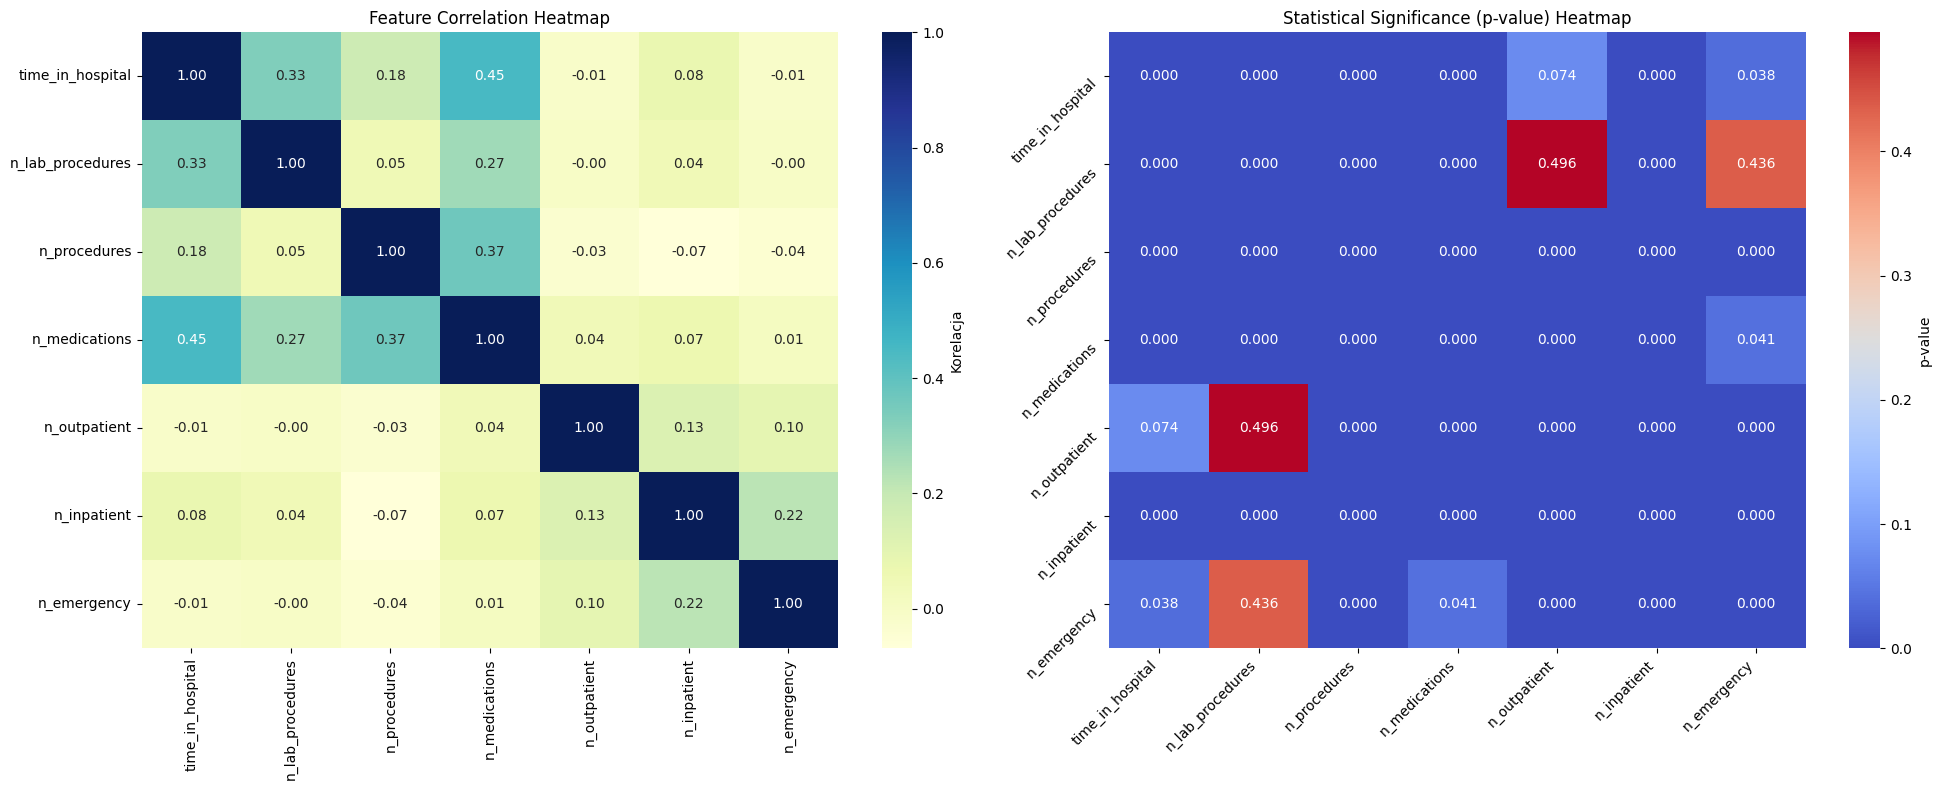

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import pearsonr
import pandas as pd

# CORRELATION FUNCTION
def correlation_with_p_value(data):
    corr_matrix = data.corr()
    p_value_matrix = np.zeros_like(corr_matrix)
    
    for i in range(len(corr_matrix.columns)):
        for j in range(len(corr_matrix.columns)):
            _, p_value_matrix[i, j] = pearsonr(data.iloc[:, i], data.iloc[:, j])
    
    return corr_matrix, p_value_matrix

# ONLY NUMERIC 
numeric_data = data.select_dtypes(include=['number'])

corr_matrix, p_value_matrix = correlation_with_p_value(numeric_data)

fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# heatmap
sns.heatmap(corr_matrix, annot=True, cmap="YlGnBu", fmt=".2f", 
            cbar_kws={'label': 'Korelacja'}, annot_kws={"size": 10}, ax=axes[0])
axes[0].set_title('Feature Correlation Heatmap')

sns.heatmap(p_value_matrix, annot=True, cmap="coolwarm", fmt=".3f", 
            cbar_kws={'label': 'p-value'}, annot_kws={"size": 10}, ax=axes[1])

axes[1].set_xticklabels(numeric_data.columns, rotation=45, ha='right')
axes[1].set_yticklabels(numeric_data.columns, rotation=45, va='top')

axes[1].set_title('Statistical Significance (p-value) Heatmap')

plt.tight_layout()
plt.show()


Correlation between time_in_hospital and n_medications: 0.4494


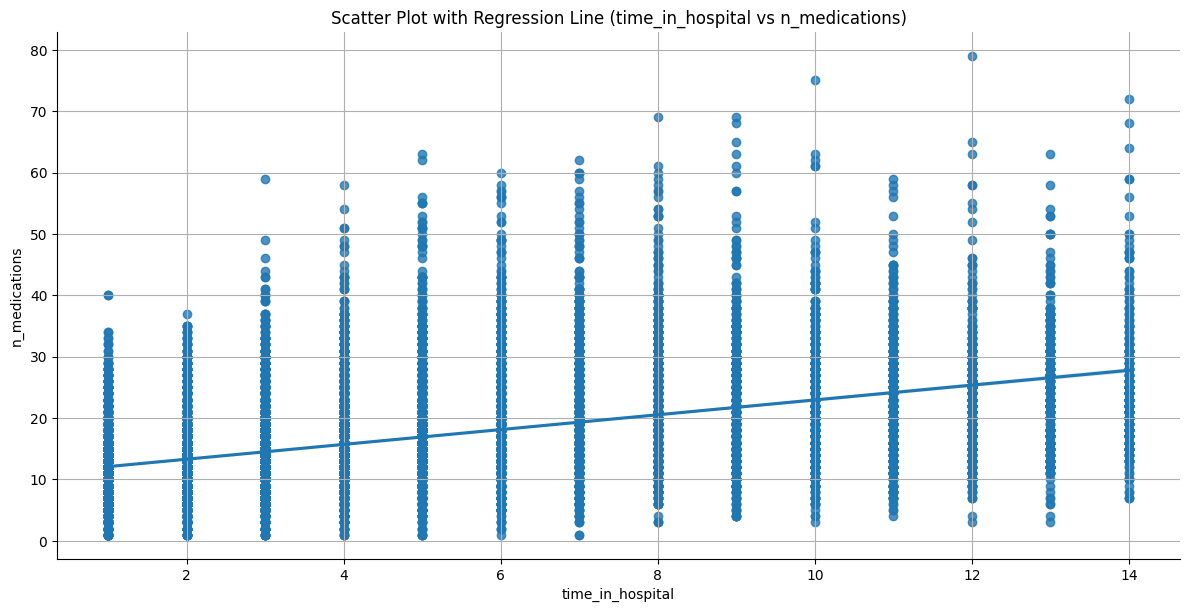

In [26]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load your dataset
data = pd.read_csv("C:\\Users\\marek\\Documents\\Datasets\\Projekt\\hospital_readmissions.csv")

var1 = 'time_in_hospital'
var2 = 'n_medications'

# Calculate the correlation coefficient
correlation_coefficient = data[var1].corr(data[var2])

print(f"Correlation between {var1} and {var2}: {correlation_coefficient:.4f}")

sns.lmplot(x=var1, y=var2, data=data, aspect=2, height=6)
plt.title(f"Scatter Plot with Regression Line ({var1} vs {var2})")
plt.xlabel(var1)
plt.ylabel(var2)
plt.grid()
plt.show()


In [29]:
import pandas as pd
import numpy as np
import statsmodels.api as sm

columns = ['time_in_hospital', 'age', 'n_lab_procedures', 'n_procedures', 
           'n_outpatient', 'n_inpatient', 'n_emergency', 'n_medications']
data_subset = data[columns].copy()


if data_subset['age'].dtype == 'object':
    data_subset['age'] = data_subset['age'].str.extract(r'(\d+)', expand=False).astype(float)

data_subset = data_subset.dropna()

X = data_subset[['time_in_hospital', 'age', 'n_lab_procedures', 'n_procedures', 
                 'n_outpatient', 'n_inpatient', 'n_emergency']]
y = data_subset['n_medications']

X = np.asarray(X, dtype=float)
y = np.asarray(y, dtype=float)


X = sm.add_constant(X)

model = sm.OLS(y, X).fit()

print(model.summary())


                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.314
Model:                            OLS   Adj. R-squared:                  0.313
Method:                 Least Squares   F-statistic:                     1632.
Date:                Thu, 19 Dec 2024   Prob (F-statistic):               0.00
Time:                        09:57:49   Log-Likelihood:                -82943.
No. Observations:               25000   AIC:                         1.659e+05
Df Residuals:                   24992   BIC:                         1.660e+05
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          9.0810      0.233     38.980      0.0

In [30]:
# Define age groups
age_groups = data['age'].unique()

# Calculate correlation for each age group
for age_group in age_groups:
    subset = data[data['age'] == age_group]
    correlation = subset['time_in_hospital'].corr(subset['n_medications'])
    print(f"Correlation for age group {age_group}: {correlation:.4f}")


Correlation for age group [70-80): 0.4432
Correlation for age group [50-60): 0.4887
Correlation for age group [60-70): 0.4517
Correlation for age group [40-50): 0.4640
Correlation for age group [80-90): 0.4519
Correlation for age group [90-100): 0.4866


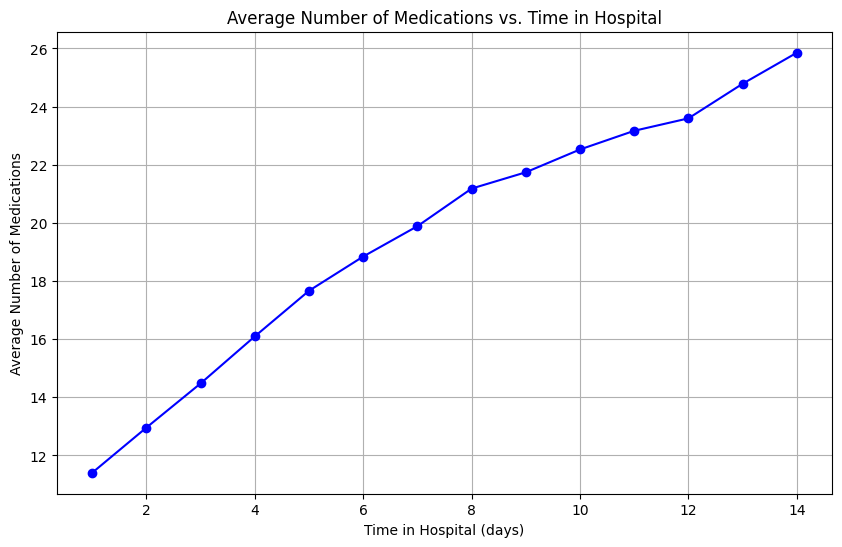

In [31]:
import matplotlib.pyplot as plt

# Group by time_in_hospital and calculate the average number of medications
temporal_trend = data.groupby('time_in_hospital')['n_medications'].mean()

# Plot the trend
plt.figure(figsize=(10, 6))
plt.plot(temporal_trend.index, temporal_trend.values, marker='o', linestyle='-', color='blue')
plt.title('Average Number of Medications vs. Time in Hospital')
plt.xlabel('Time in Hospital (days)')
plt.ylabel('Average Number of Medications')
plt.grid()
plt.show()


In [34]:
from scipy.stats import pearsonr

medications = data['n_medications']

readmission_probabilities = model.predict(X)

# Calculate the Pearson correlation coefficient
correlation, _ = pearsonr(medications, readmission_probabilities)

print(f"Pearson Correlation Coefficient: {correlation:.4f}")


Pearson Correlation Coefficient: 0.5601
